# Categorical plots

## Learning objectives

By the end of this notebook you will be able to:

- count categories with countplot
- show means and uncertainty with barplot and pointplot
- compare distributions across groups with box, violin, strip and swarm plots
- use catplot for panels

## Introduction

Many questions compare a numeric value across categories: glucose by treatment group, tips by day,
positivity by sample type. Seaborn has a family of plots for this, from simple counts to full
distributions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
RAW = "../datasets/raw/"

In [2]:
sns.set_theme(style="whitegrid")
tips = sns.load_dataset("tips")
titanic = sns.load_dataset("titanic")
penguins = sns.load_dataset("penguins")

## countplot: how many in each category

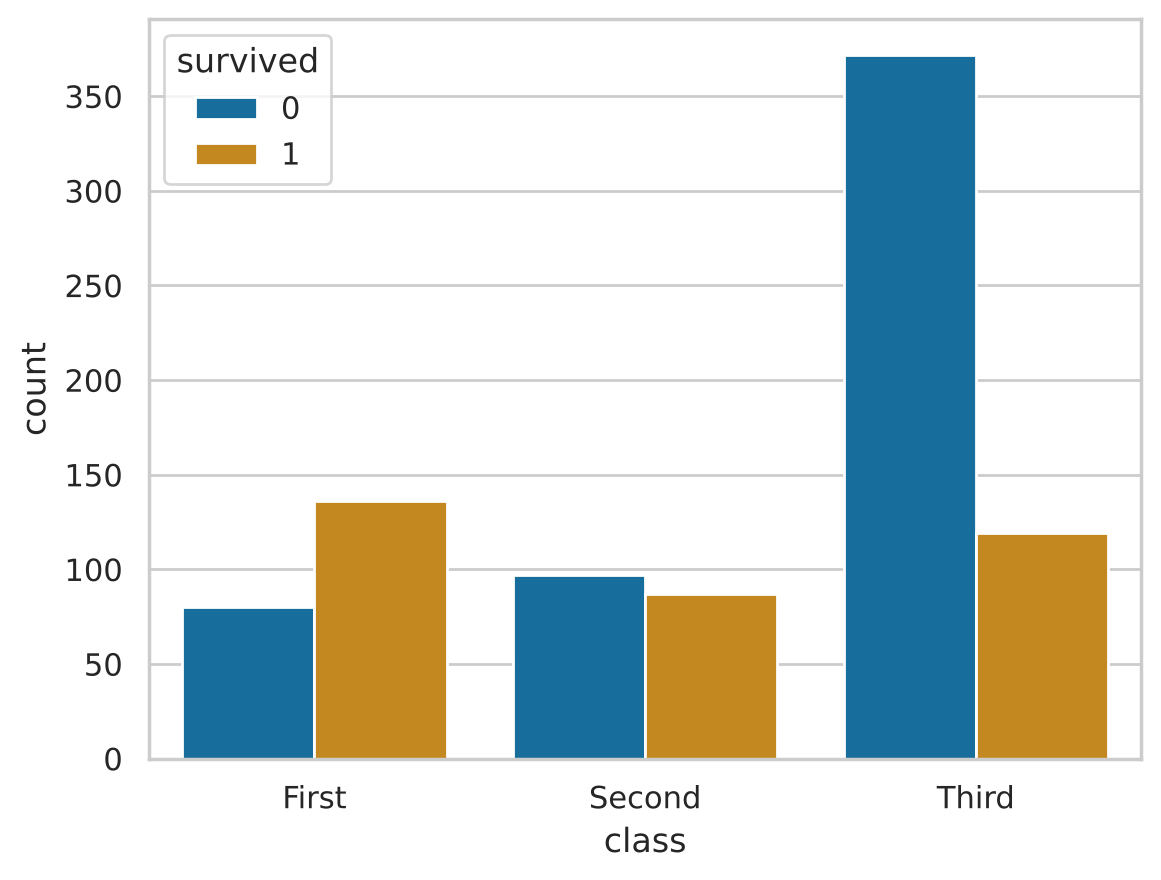

In [3]:
sns.countplot(data=titanic, x="class", hue="survived", palette="colorblind")
plt.show()

Pass `order=` to control the category order and `stat="percent"` for percentages. Horizontal bars,
sorted by count, suit many categories:

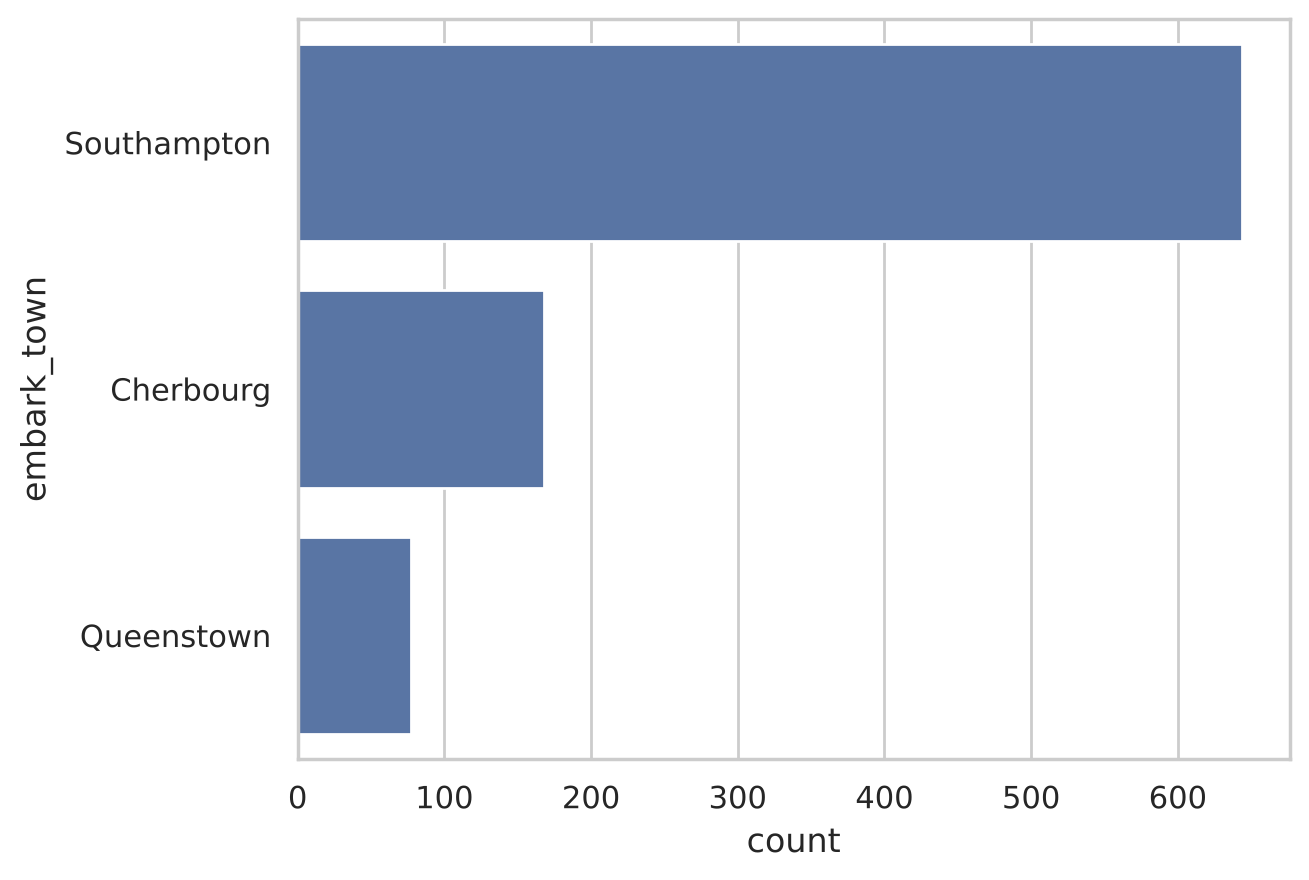

In [4]:
order = titanic["embark_town"].value_counts().index
sns.countplot(data=titanic, y="embark_town", order=order)
plt.show()

## barplot: a summary with uncertainty

`barplot` shows the **mean** of y for each category, with an error bar. By default, the error bar is a
95% confidence interval computed by resampling (bootstrapping).

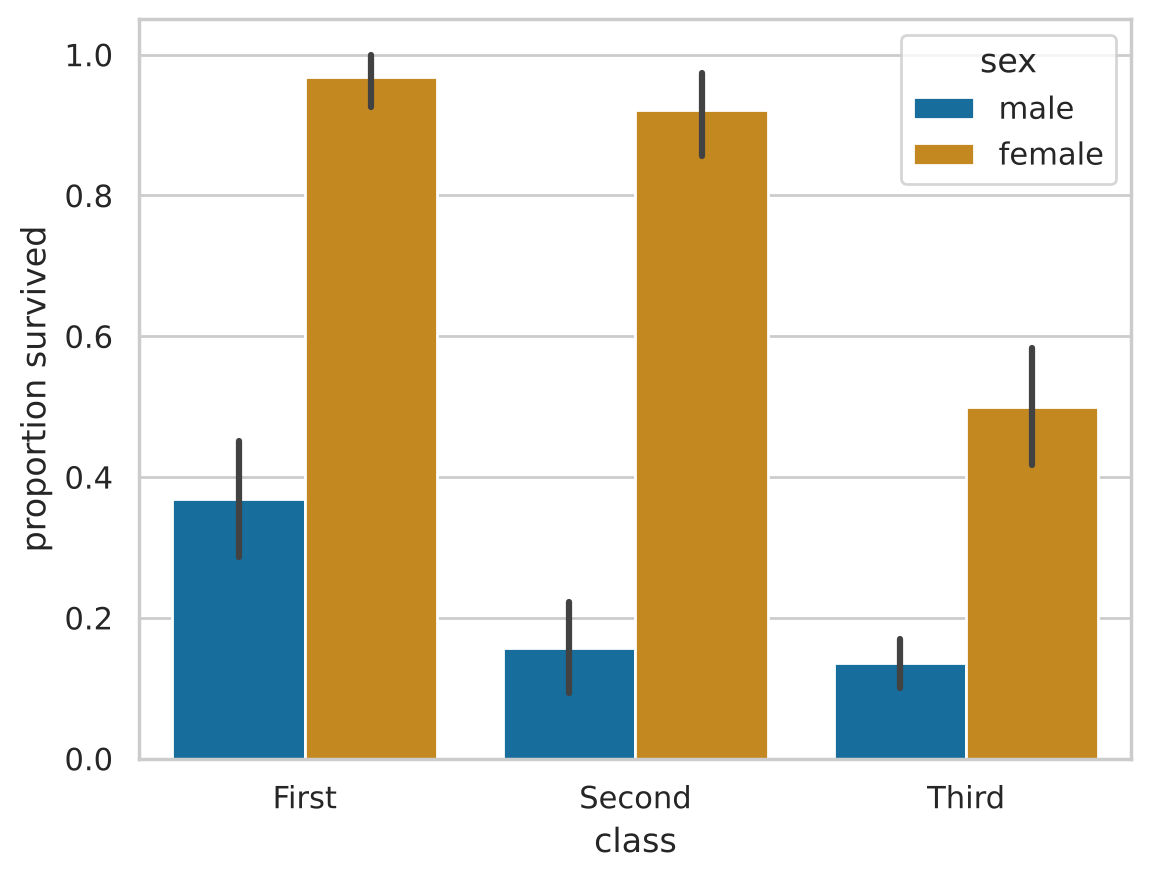

In [5]:
sns.barplot(data=titanic, x="class", y="survived", hue="sex", palette="colorblind")
plt.ylabel("proportion survived")
plt.show()

The mean of a 0/1 column is a proportion, so the bars are survival rates. Women survived far more often
than men in every class, and survival fell from first to third class.

`errorbar=` chooses what the bars show: `("ci", 95)`, `"se"` (standard error), `"sd"` (standard
deviation), or `None`.

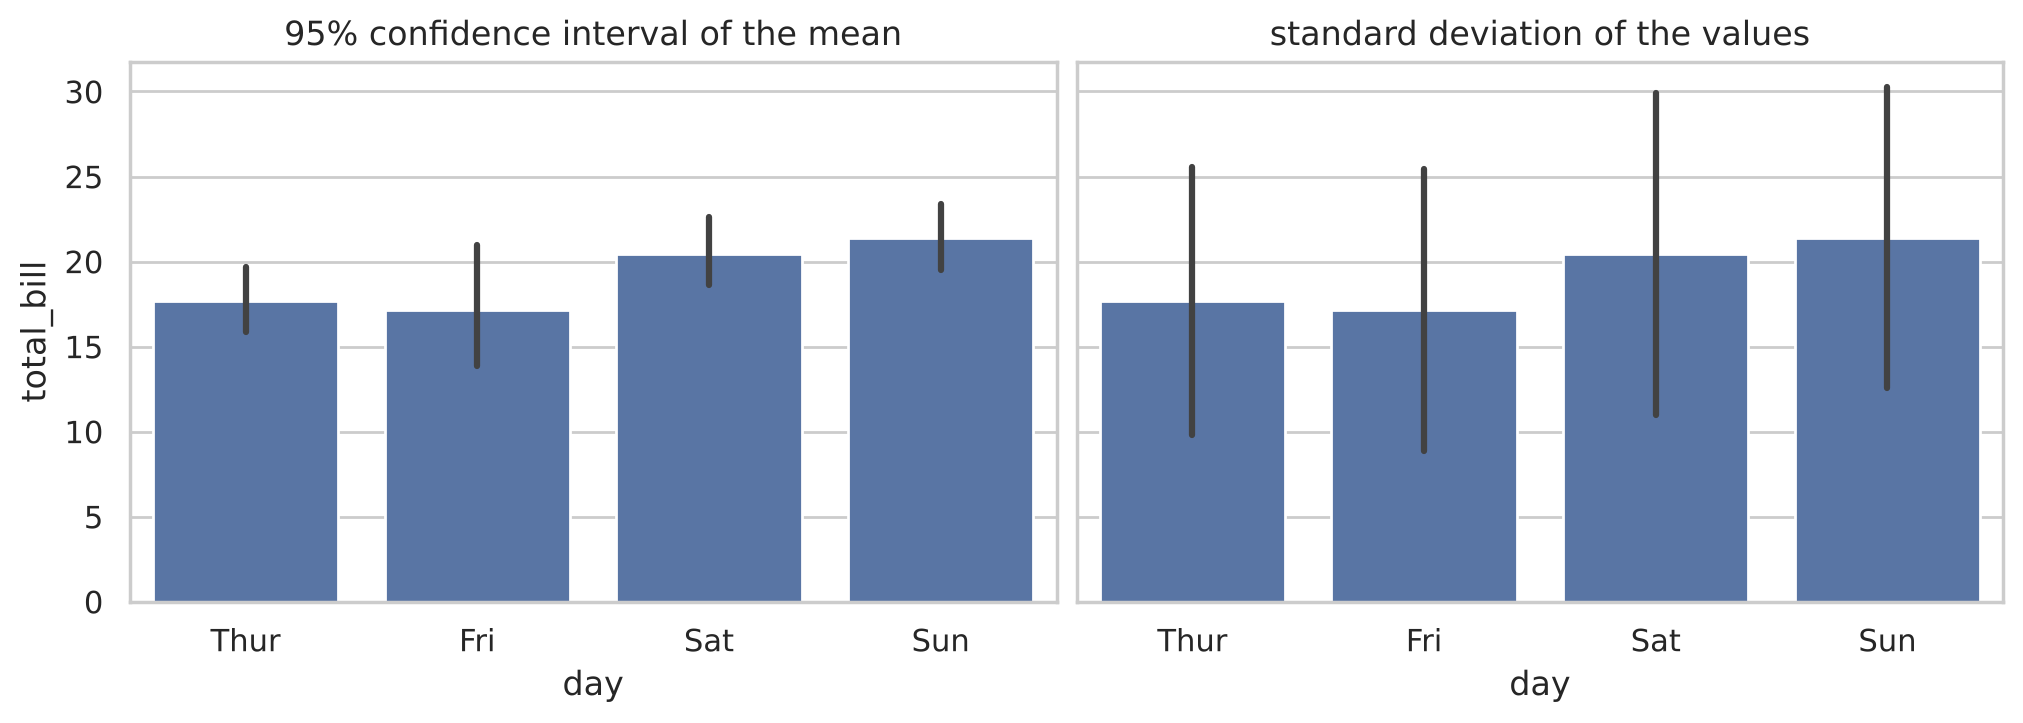

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout="constrained")
sns.barplot(data=tips, x="day", y="total_bill", errorbar=("ci", 95), ax=axes[0])
sns.barplot(data=tips, x="day", y="total_bill", errorbar="sd", ax=axes[1])
axes[0].set_title("95% confidence interval of the mean")
axes[1].set_title("standard deviation of the values")
plt.show()

The confidence interval describes the uncertainty in the **mean**; the standard deviation describes the
spread of the **individual values**, and is wider. Always say which one you show.

A bar of the mean hides the distribution. When the distribution matters, use the plots below.

## boxplot

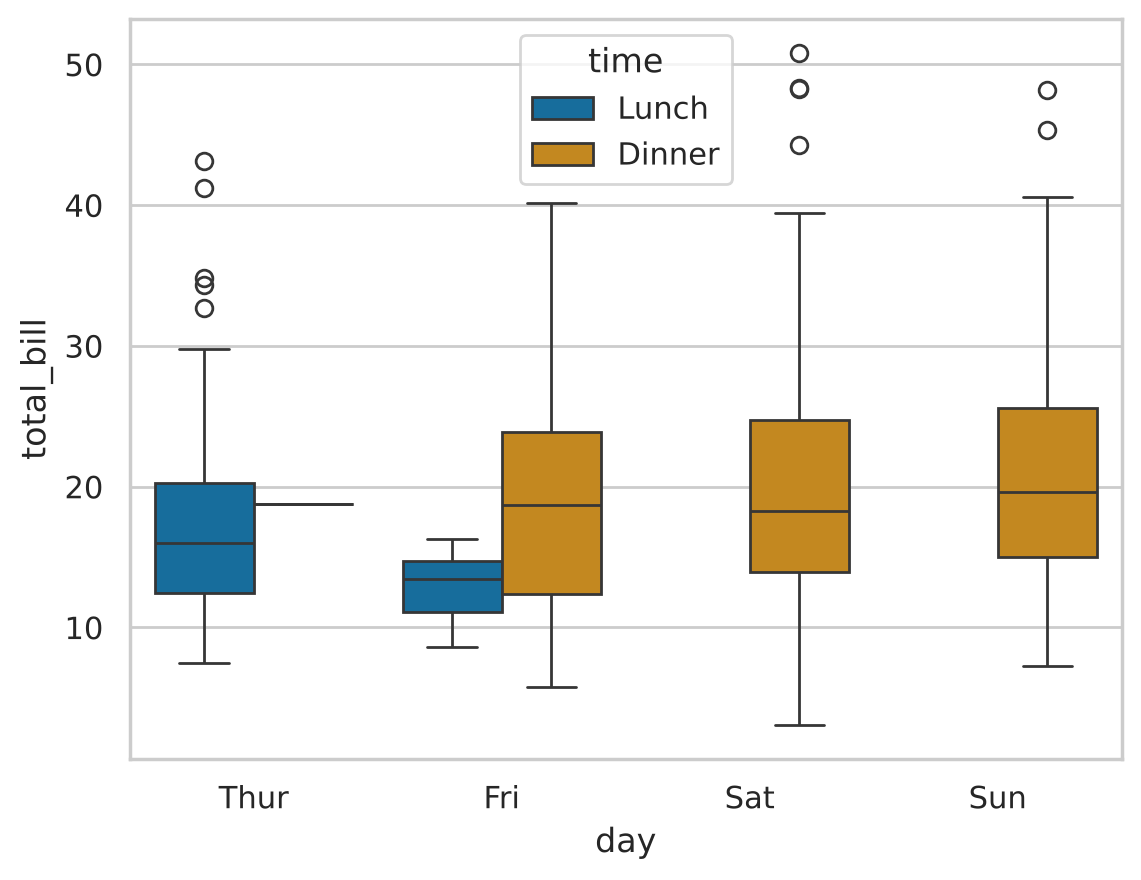

In [7]:
sns.boxplot(data=tips, x="day", y="total_bill", hue="time", palette="colorblind")
plt.show()

## violinplot

A violin is a box plot with a density curve on each side, so it also shows the shape (two humps, a long
tail).

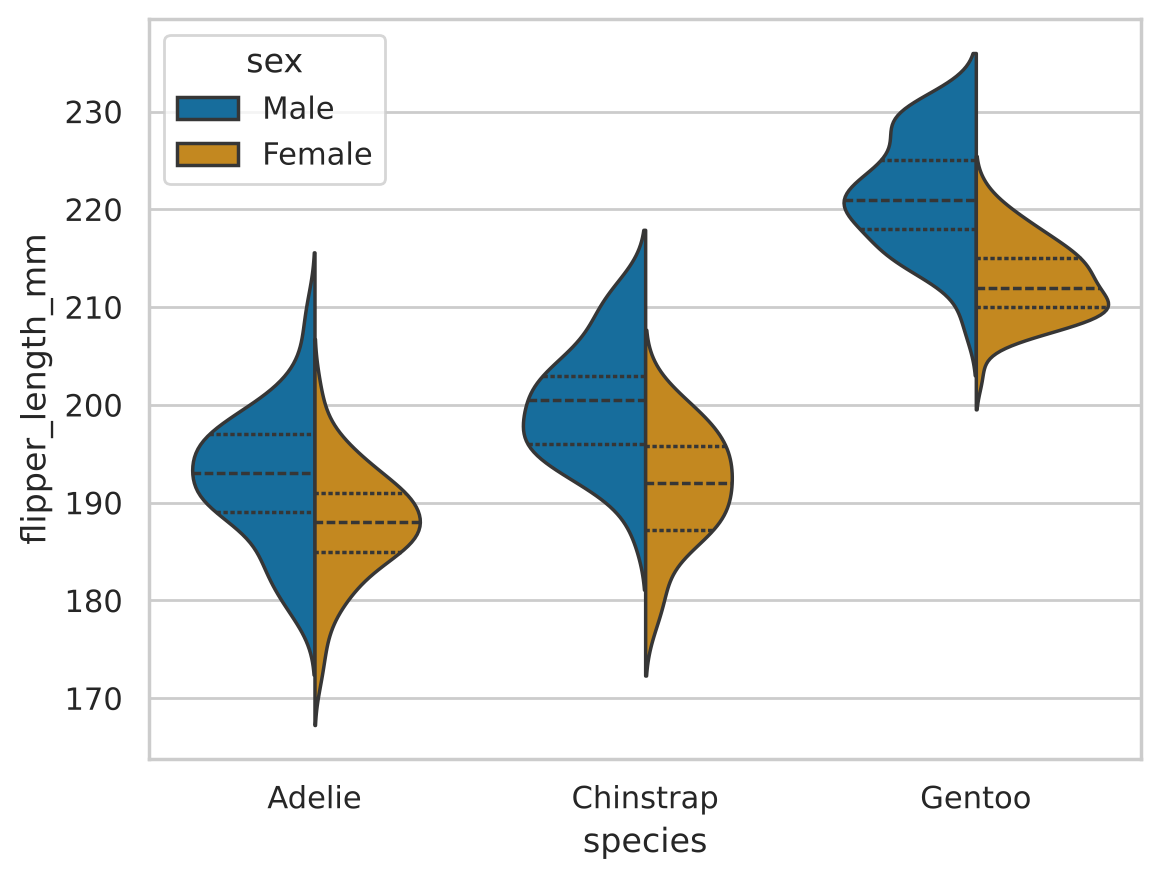

In [8]:
sns.violinplot(data=penguins, x="species", y="flipper_length_mm", hue="sex", split=True,
               inner="quart", palette="colorblind")
plt.show()

`split=True` draws the two sexes as halves of one violin; `inner="quart"` adds lines at the quartiles.

## strip and swarm plots: every observation

With small or moderate samples, showing each point is the most honest option.

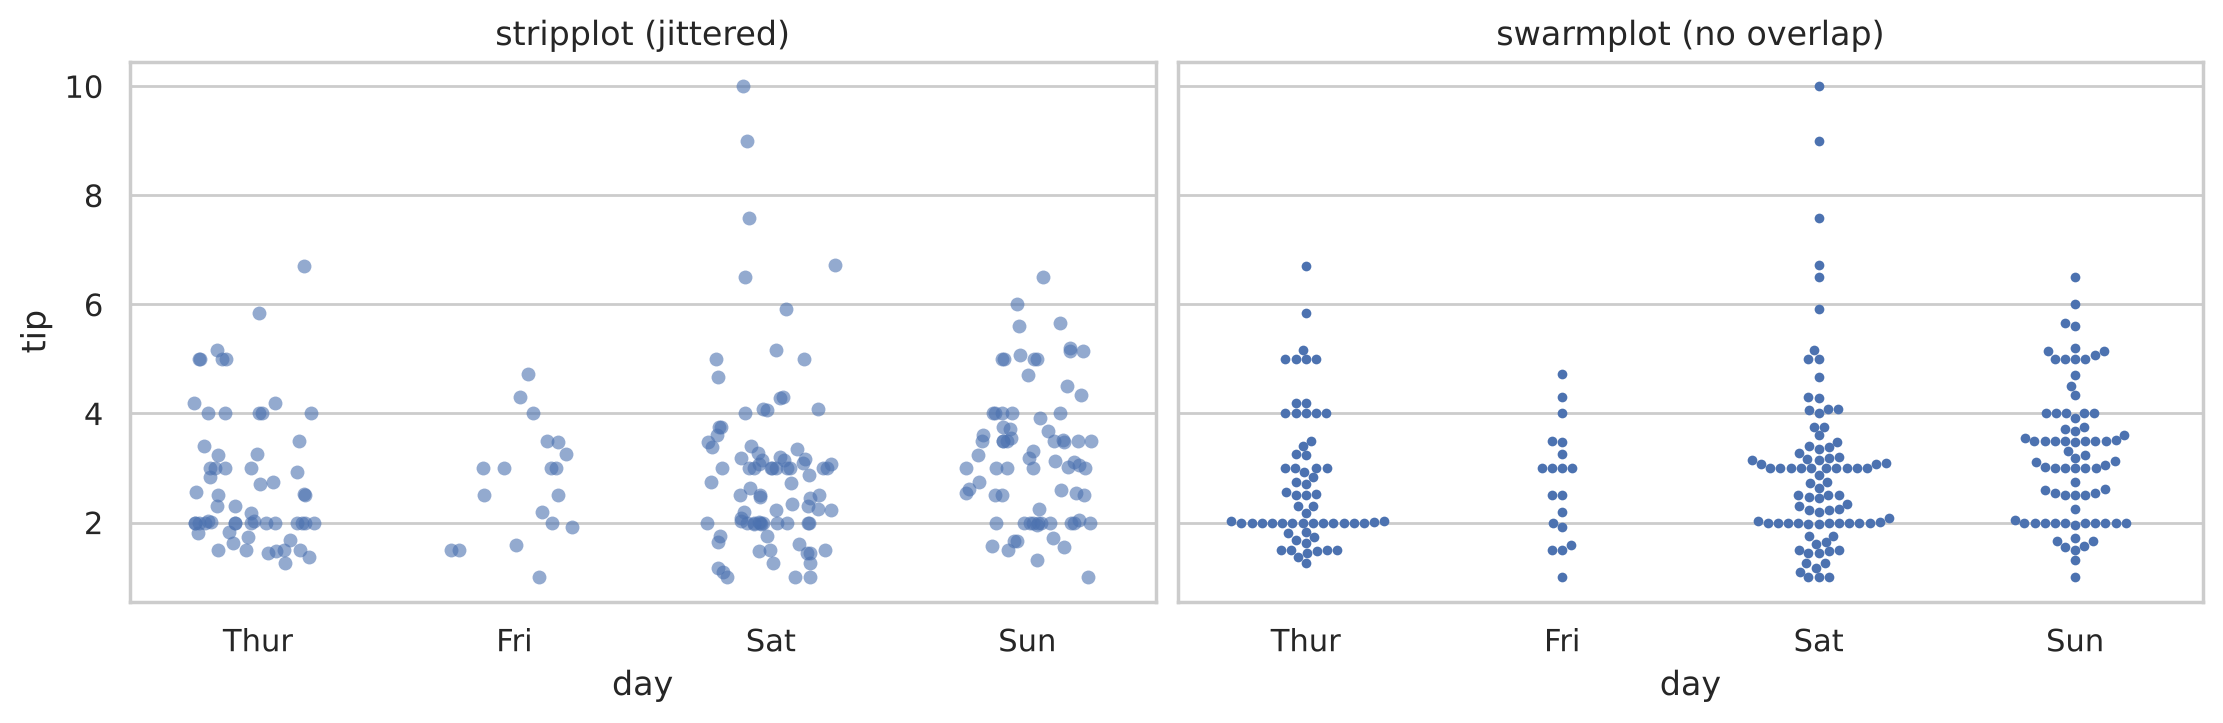

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True, layout="constrained")
sns.stripplot(data=tips, x="day", y="tip", alpha=0.6, jitter=0.25, ax=axes[0])
sns.swarmplot(data=tips, x="day", y="tip", size=3.5, ax=axes[1])
axes[0].set_title("stripplot (jittered)")
axes[1].set_title("swarmplot (no overlap)")
plt.show()

## Combining layers: box plus points

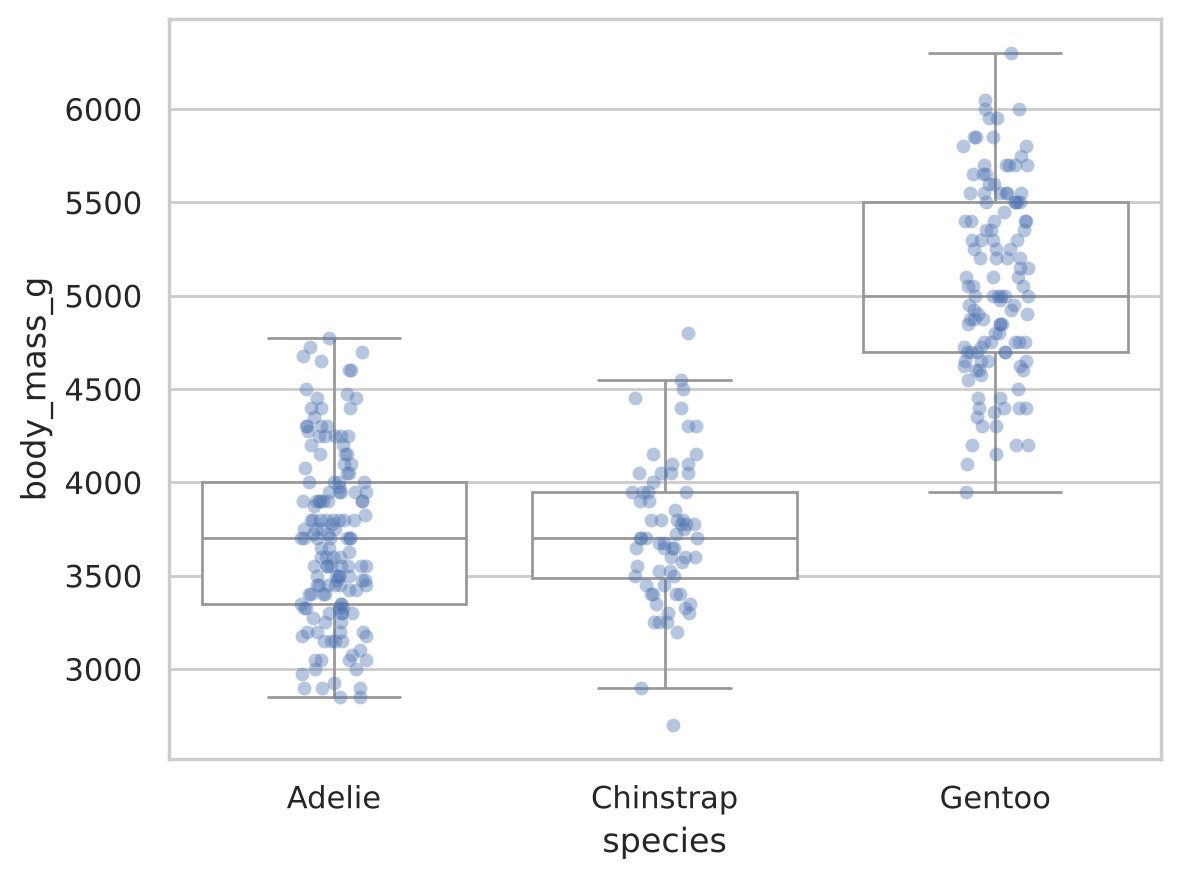

In [10]:
ax = sns.boxplot(data=penguins, x="species", y="body_mass_g", color="white", showfliers=False)
sns.stripplot(data=penguins, x="species", y="body_mass_g", alpha=0.4, ax=ax)
plt.show()

`showfliers=False` hides the box plot's own outlier points, because the strip plot already shows every
point.

## pointplot: means joined across categories

Good for showing how group means change across an ordered factor, and for interactions:

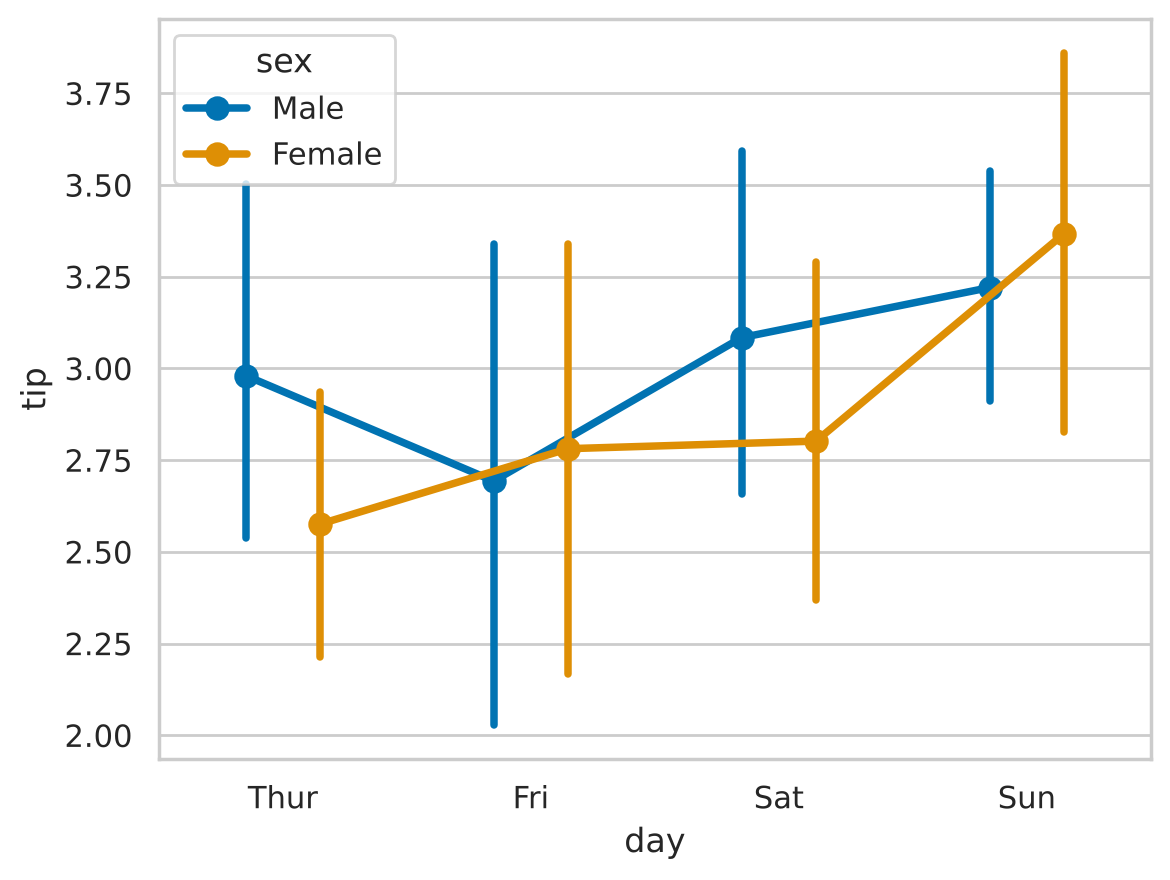

In [11]:
sns.pointplot(data=tips, x="day", y="tip", hue="sex", dodge=0.3, palette="colorblind",
              order=["Thur", "Fri", "Sat", "Sun"])
plt.show()

## catplot: panels

The figure-level `catplot` gives any of these with `kind=` and panels with `col`/`row`:

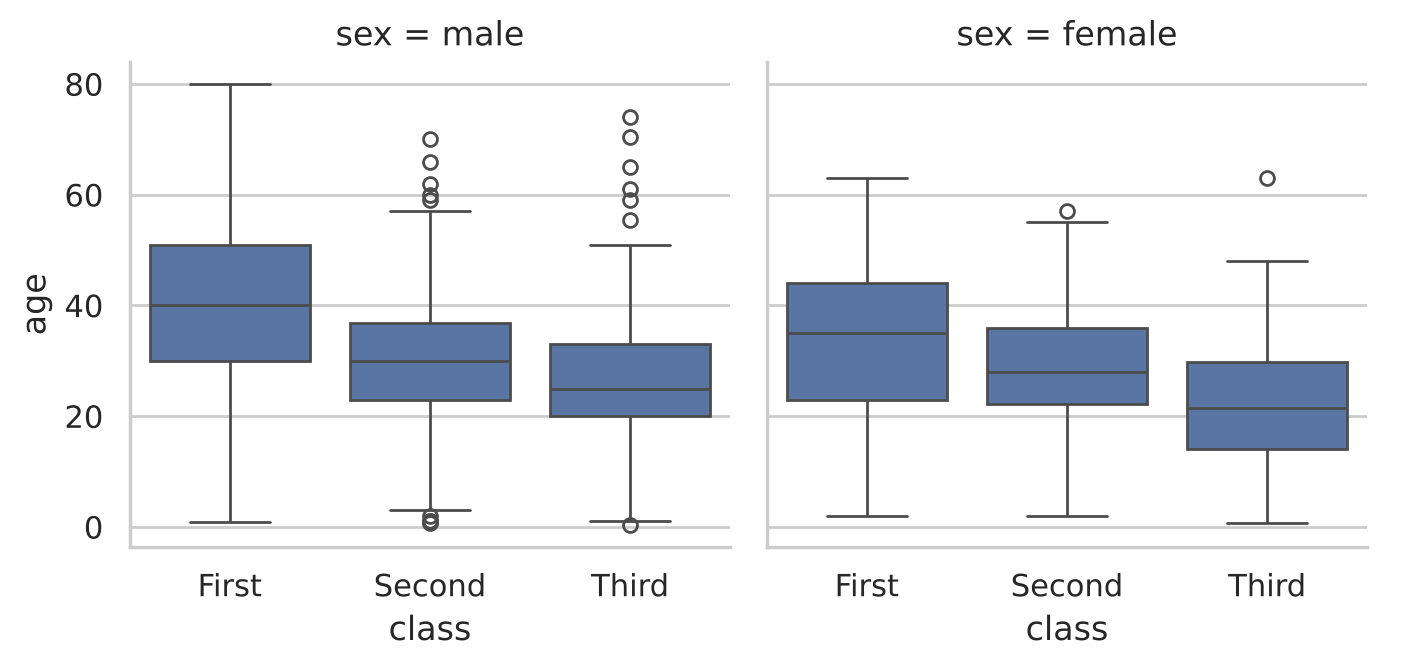

In [12]:
sns.catplot(data=titanic, x="class", y="age", kind="box", col="sex", height=3.5, aspect=1)
plt.show()

## Course data: glucose by group and visit

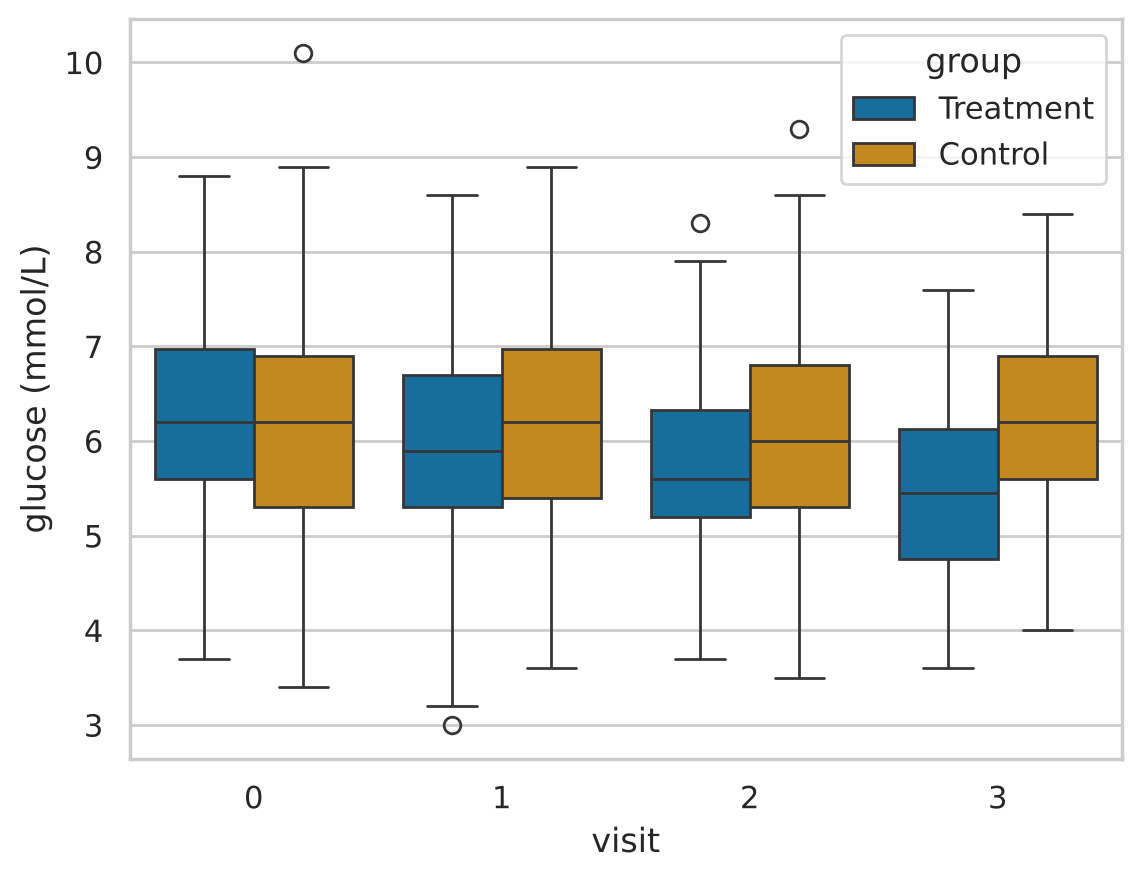

In [13]:
labs = pd.read_csv(RAW + "lab_results.csv")
patients = pd.read_csv(RAW + "patients.csv")
df = labs.merge(patients[["patient_id", "group"]], on="patient_id")
sns.boxplot(data=df, x="visit", y="glucose_mmol", hue="group", palette="colorblind")
plt.ylabel("glucose (mmol/L)")
plt.show()

## Practise

Exercises for this folder are in `exercises/Seaborn_Exercises.ipynb`.

## Further reading

- [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html)
- [Visualising categorical data](https://seaborn.pydata.org/tutorial/categorical.html)
- [Statistical estimation and error bars](https://seaborn.pydata.org/tutorial/error_bars.html)